In [ ]:
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
from scipy.optimize import minimize_scalar, minimize
%matplotlib inline

#setting up the environment
C     = 1.0
A     = 2.0
A0    = 0.0
MU    = 0.25
DELTA = 0.95


#functions from main SAC code
def demand(pi, pj):
    num = np.exp((A - pi) / MU)
    return num / (num + np.exp((A - pj) / MU) + np.exp(A0 / MU))


def profit(pi, pj):
    return (pi - C) * demand(pi, pj)

def neg_joint(prices):
  p1, p2 = prices
  return -profit(p1, p2) - profit(p2, p1)

def compute_benchmarks():
  #intial guess
  p = 1.5
    #1000 iterations
  for _ in range(1000):
        #minimising negative of the profit
        res = minimize_scalar(lambda pi, pj=p: -(pi - C) * demand(pi, pj),
                              bounds=(C, C + 3), method="bounded")
        #tolerance
        if abs(res.x - p) < 1e-10:
            break
        p = res.x
  p_nash = p
  pi_nash = profit(p_nash, p_nash)
  #monopoly
  res = minimize(neg_joint, [1.8, 1.8], bounds=[(C, C + 3)] * 2)
  p_mono = res.x[0]
  pi_mono = -neg_joint(res.x) / 2
  return p_nash, p_mono, pi_nash, pi_mono



P_NASH, P_MONO, PI_NASH, PI_MONO = compute_benchmarks()
SPREAD = P_MONO - P_NASH
P_MIN  = P_NASH - 0.3 * SPREAD
P_MAX  = P_MONO + 0.3 * SPREAD

print(f"p_nash = {P_NASH:.4f}   p_mono = {P_MONO:.4f}")
print(f"pi_nash = {PI_NASH:.4f}   pi_mono = {PI_MONO:.4f}")
print(f"p_range = [{P_MIN:.4f}, {P_MAX:.4f}]")


p_nash = 1.4729   p_mono = 1.9250
pi_nash = 0.2229   pi_mono = 0.3375
p_range = [1.3373, 2.0606]


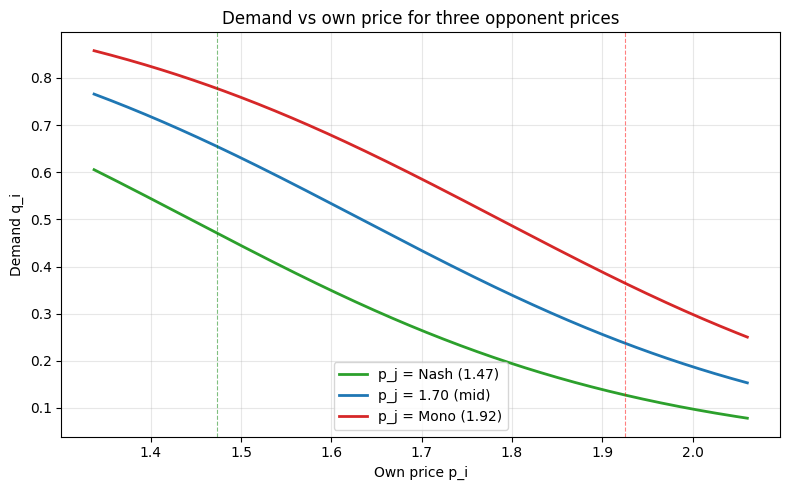

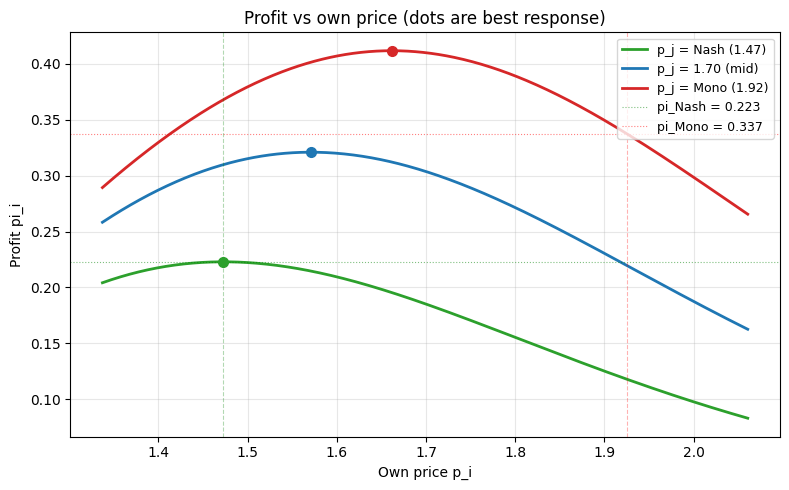

In [ ]:
#sweeping price
p_sweep = np.linspace(P_MIN, P_MAX, 500)
p_mid = (P_NASH + P_MONO) / 2

#three oppononnt price levels
pj_vals = [P_NASH, p_mid, P_MONO]
pj_labels = ["p_j = Nash (%.2f)" % P_NASH,
             "p_j = %.2f (mid)" % p_mid,
             "p_j = Mono (%.2f)" % P_MONO]
cols = ["#2ca02c", "#1f77b4", "#d62728"]

#plotting demand curves
fig, ax = plt.subplots(figsize=(8, 5))
for pj, lab, c in zip(pj_vals, pj_labels, cols):
    ax.plot(p_sweep, [demand(p, pj) for p in p_sweep], lw=2, label=lab, color=c)

ax.axvline(P_NASH, color="green", ls="--", lw=0.8, alpha=0.5)
ax.axvline(P_MONO, color="red", ls="--", lw=0.8, alpha=0.5)
ax.set_xlabel("Own price p_i")
ax.set_ylabel("Demand q_i")
ax.set_title("Demand vs own price for three opponent prices")
ax.legend()
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

#plotting BR curves
fig, ax = plt.subplots(figsize=(8, 5))
for pj, lab, c in zip(pj_vals, pj_labels, cols):
    pi_vals = [profit(p, pj) for p in p_sweep]
    ax.plot(p_sweep, pi_vals, lw=2, label=lab, color=c)

    #marking the peak
    br = minimize_scalar(lambda p: -profit(p, pj),
                         bounds=(P_MIN, P_MAX), method="bounded")
    ax.plot(br.x, profit(br.x, pj), "o", color=c, ms=7, zorder=5)

ax.axhline(PI_NASH, color="green", ls=":", lw=0.8, alpha=0.5,
           label="pi_Nash = %.3f" % PI_NASH)
ax.axhline(PI_MONO, color="red", ls=":", lw=0.8, alpha=0.5,
           label="pi_Mono = %.3f" % PI_MONO)
ax.axvline(P_NASH, color="green", ls="--", lw=0.8, alpha=0.3)
ax.axvline(P_MONO, color="red", ls="--", lw=0.8, alpha=0.3)
ax.set_xlabel("Own price p_i")
ax.set_ylabel("Profit pi_i")
ax.set_title("Profit vs own price (dots are best response)")
ax.legend(fontsize=9, loc="upper right")
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

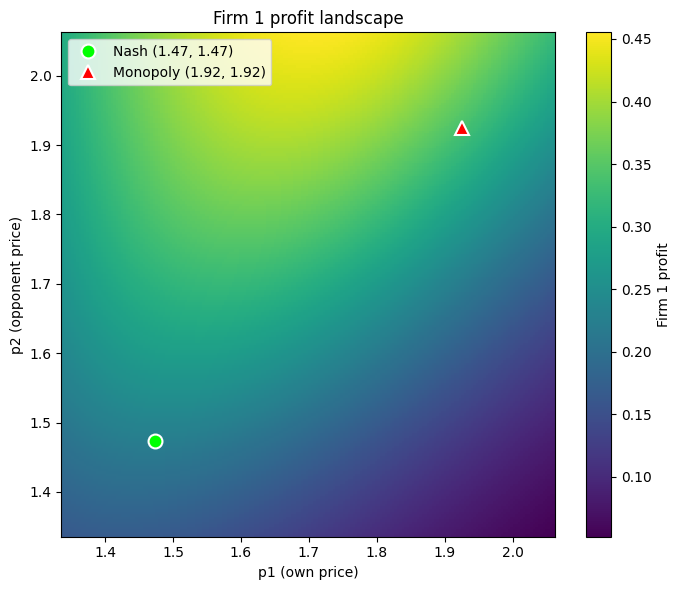

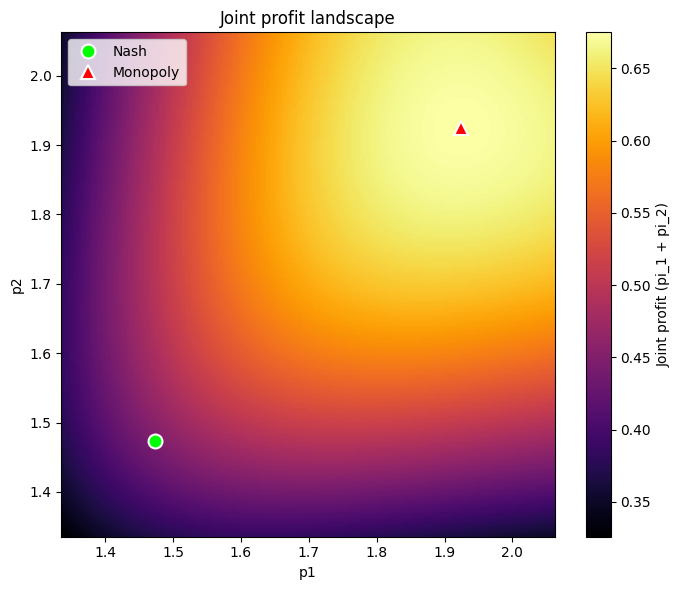

In [ ]:
#grid for the profit heatmap
N_GRID = 200
p1_grid = np.linspace(P_MIN, P_MAX, N_GRID)
p2_grid = np.linspace(P_MIN, P_MAX, N_GRID)
P1, P2 = np.meshgrid(p1_grid, p2_grid)
PI1 = np.vectorize(profit)(P1, P2)

#firm 1 profit heatmap
fig, ax = plt.subplots(figsize=(7, 6))
im = ax.pcolormesh(p1_grid, p2_grid, PI1, cmap="viridis", shading="auto")
cbar = fig.colorbar(im, ax=ax)
cbar.set_label("Firm 1 profit")

ax.plot(P_NASH, P_NASH, "o", color="lime", ms=10, markeredgecolor="white",
        markeredgewidth=1.5, label="Nash (%.2f, %.2f)" % (P_NASH, P_NASH), zorder=5)
ax.plot(P_MONO, P_MONO, "^", color="red", ms=10, markeredgecolor="white",
        markeredgewidth=1.5, label="Monopoly (%.2f, %.2f)" % (P_MONO, P_MONO), zorder=5)

ax.set_xlabel("p1 (own price)")
ax.set_ylabel("p2 (opponent price)")
ax.set_title("Firm 1 profit landscape")
ax.legend(loc="upper left")
plt.tight_layout()
plt.show()

#joint profit heatmap
def joint_profit(p1, p2):
    return profit(p1, p2) + profit(p2, p1)

PI_JOINT = np.vectorize(joint_profit)(P1, P2)

fig, ax = plt.subplots(figsize=(7, 6))
im = ax.pcolormesh(p1_grid, p2_grid, PI_JOINT, cmap="inferno", shading="auto")
cbar = fig.colorbar(im, ax=ax)
cbar.set_label("Joint profit (pi_1 + pi_2)")

ax.plot(P_NASH, P_NASH, "o", color="lime", ms=10, markeredgecolor="white",
        markeredgewidth=1.5, label="Nash", zorder=5)
ax.plot(P_MONO, P_MONO, "^", color="red", ms=10, markeredgecolor="white",
        markeredgewidth=1.5, label="Monopoly", zorder=5)

ax.set_xlabel("p1")
ax.set_ylabel("p2")
ax.set_title("Joint profit landscape")
ax.legend(loc="upper left")
plt.tight_layout()
plt.show()

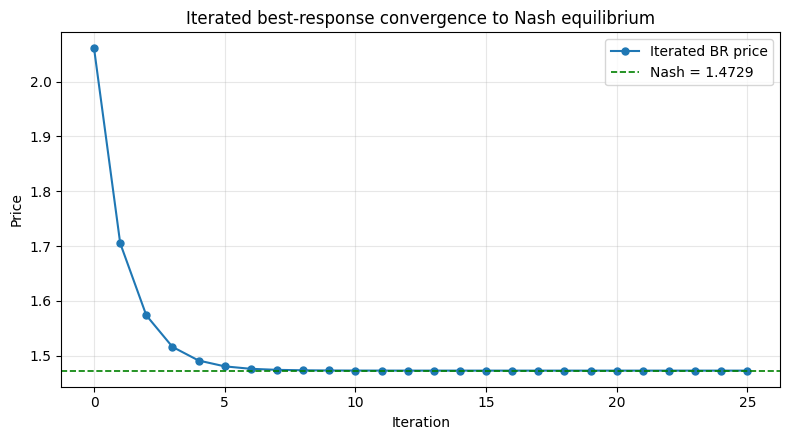

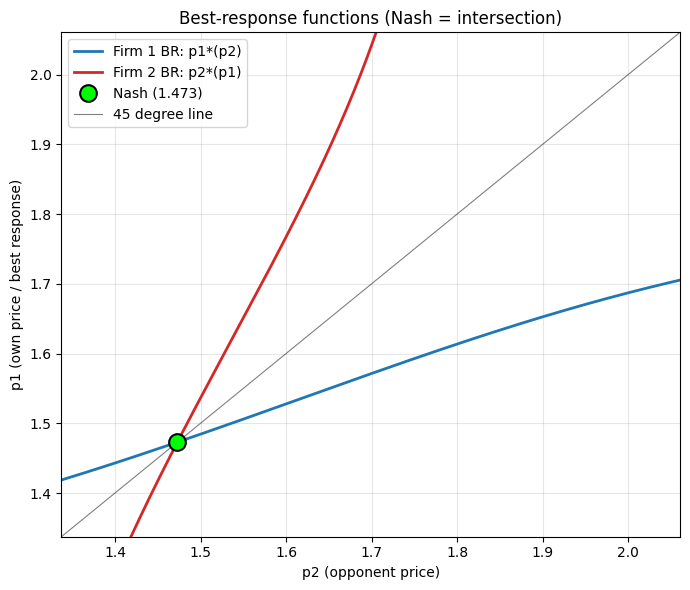

  Nash price       p_N  = 1.4729
  Monopoly price   p_M  = 1.9250
  Nash profit      pi_N = 0.2229
  Monopoly profit  pi_M = 0.3375
  Price range      [1.3373, 2.0606]
  Spread           p_M - p_N = 0.4521
  Margin           30% x spread = 0.1356


In [ ]:
#iterated best respone convergence
def best_response(pj):
    res = minimize_scalar(lambda pi: -profit(pi, pj),
                          bounds=(P_MIN, P_MAX), method="bounded")
    return res.x

ibr_path = [P_MAX]
for i in range(25):
    ibr_path.append(best_response(ibr_path[-1]))

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(ibr_path, "o-", ms=5, lw=1.5, color="#1f77b4", label="Iterated BR price")
ax.axhline(P_NASH, color="green", ls="--", lw=1.2, label="Nash = %.4f" % P_NASH)
ax.set_xlabel("Iteration")
ax.set_ylabel("Price")
ax.set_title("Iterated best-response convergence to Nash equilibrium")
ax.legend()
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

#plotting BR
br_sweep = np.linspace(P_MIN, P_MAX, 300)
br_vals = np.zeros(len(br_sweep))
for i in range(len(br_sweep)):
    br_vals[i] = best_response(br_sweep[i])

fig, ax = plt.subplots(figsize=(7, 6))
ax.plot(br_sweep, br_vals, lw=2, color="#1f77b4", label="Firm 1 BR: p1*(p2)")
ax.plot(br_vals, br_sweep, lw=2, color="#d62728", label="Firm 2 BR: p2*(p1)")
ax.plot(P_NASH, P_NASH, "o", color="lime", ms=12, markeredgecolor="black",
        markeredgewidth=1.5, label="Nash (%.3f)" % P_NASH, zorder=5)
ax.plot([P_MIN, P_MAX], [P_MIN, P_MAX], color="black", lw=0.8, alpha=0.5,
        label="45 degree line")
ax.set_xlabel("p2 (opponent price)")
ax.set_ylabel("p1 (own price / best response)")
ax.set_title("Best-response functions (Nash = intersection)")
ax.legend()
ax.grid(True, alpha=0.3)
ax.set_xlim(P_MIN, P_MAX)
ax.set_ylim(P_MIN, P_MAX)
plt.tight_layout()
plt.show()

# ── benchmark summary table ──
print("  Nash price       p_N  = %.4f" % P_NASH)
print("  Monopoly price   p_M  = %.4f" % P_MONO)
print("  Nash profit      pi_N = %.4f" % PI_NASH)
print("  Monopoly profit  pi_M = %.4f" % PI_MONO)
print("  Price range      [%.4f, %.4f]" % (P_MIN, P_MAX))
print("  Spread           p_M - p_N = %.4f" % SPREAD)
print("  Margin           30%% x spread = %.4f" % (0.3 * SPREAD))

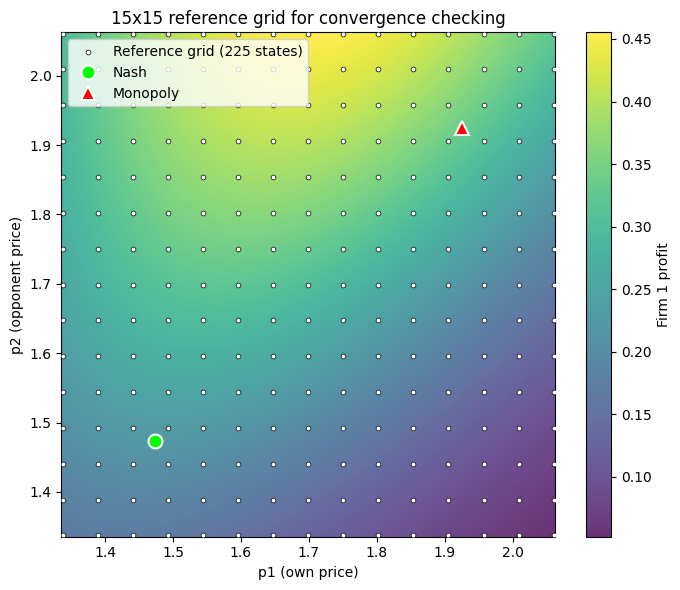

In [ ]:
#setting up reference grid
N_REF = 15
ref_prices = np.linspace(P_MIN, P_MAX, N_REF)
ref_p1, ref_p2 = np.meshgrid(ref_prices, ref_prices)


#plotting
fig, ax = plt.subplots(figsize=(7, 6))
im = ax.pcolormesh(p1_grid, p2_grid, PI1, cmap="viridis", shading="auto", alpha=0.8)
cbar = fig.colorbar(im, ax=ax)
cbar.set_label("Firm 1 profit")

ax.scatter(ref_p1.ravel(), ref_p2.ravel(), s=12, color="white", edgecolors="black",
           linewidths=0.5, zorder=4, label="Reference grid (225 states)")

ax.plot(P_NASH, P_NASH, "o", color="lime", ms=10, markeredgecolor="white",
        markeredgewidth=1.5, label="Nash", zorder=5)
ax.plot(P_MONO, P_MONO, "^", color="red", ms=10, markeredgecolor="white",
        markeredgewidth=1.5, label="Monopoly", zorder=5)

ax.set_xlabel("p1 (own price)")
ax.set_ylabel("p2 (opponent price)")
ax.set_title("15x15 reference grid for convergence checking")
ax.legend(loc="upper left")
plt.tight_layout()
plt.show()